# Thesis figures, one per cell

Each figure below is drawn by its own cell, reading its own data straight out of the committed
result files under `results/accord/`. No cell depends on any variable another figure's cell
created; each one loads what it needs, prints the values it is about to plot, draws, displays the
figure inline, and saves it as a PDF.

Run cells 1 to 3 first (setup, palette, small shared helpers). After that, every figure cell below
runs on its own, in any order.

**No credentialed data is shipped here.** MIMIC-III is a PhysioNet-credentialed dataset; every
result file this notebook reads is an aggregate (counts, rates, confusion-matrix cells, bootstrap
intervals) with no clinical text and no patient or admission identifiers.

## 1. Setup

In [1]:
%matplotlib inline
import os, sys, shutil, json, pathlib, math, statistics
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import norm
from scipy.optimize import brentq
import pandas as pd

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_BUNDLE = "/content/drive/MyDrive/This is paper/02_figures/colab_bundle"
    REPO = "/content/repo"
    os.makedirs(REPO, exist_ok=True)
    dst_results = os.path.join(REPO, "results")
    if os.path.exists(dst_results):
        shutil.rmtree(dst_results)
    shutil.copytree(os.path.join(DRIVE_BUNDLE, "results"), dst_results)
    print(f"copied bundle results: {DRIVE_BUNDLE}/results -> {dst_results}")
else:
    # Local run: this machine already has the repository checked out, so there is
    # nothing to mount or copy. REPO points straight at it.
    REPO = "/Users/rickygole/provenance-encoder"
    print(f"not running in Colab; reading directly from the local repository at {REPO}")

RESULTS = os.path.join(REPO, "results")
RESULTS_ACCORD = os.path.join(RESULTS, "accord")
FIGDIR = os.path.join(REPO, "accord", "thesis", "figures")
os.makedirs(FIGDIR, exist_ok=True)

# Defensive only: no cell in this notebook resamples or fits anything. Every
# bootstrap interval plotted below was already computed upstream (the seed is
# recorded inside the source JSON, typically 42) and is simply read and plotted.
np.random.seed(42)

n_json = sum(1 for _ in pathlib.Path(RESULTS_ACCORD).rglob("*.json"))
print("REPO           =", REPO)
print("RESULTS_ACCORD =", RESULTS_ACCORD)
print("FIGDIR         =", FIGDIR)
print("json files under results/accord:", n_json)

not running in Colab; reading directly from the local repository at /Users/rickygole/provenance-encoder
REPO           = /Users/rickygole/provenance-encoder
RESULTS_ACCORD = /Users/rickygole/provenance-encoder/results/accord
FIGDIR         = /Users/rickygole/provenance-encoder/accord/thesis/figures
json files under results/accord: 93


## 2. Shared palette

Four colours plus a red accent, used by name in every figure cell below (`DARK`, `MID`, `FILL`,
`DEAD`, `RED`). They differ in **lightness**, not just hue, so the figures still separate correctly
in a black-and-white print; the readout below prints that separation. This is the same palette
already established for this bundle in `Thesis_Figures_Restyle.ipynb`.

In [2]:
DARK = "#1f3a5f"   # bars, lines, primary emphasis
MID  = "#7f8c9b"   # secondary series, reference lines, muted text
FILL = "#cdd7e0"   # bar fills, shaded bands
DEAD = "#b0b6bd"   # de-emphasised or retracted elements
RED  = "#b03030"   # used sparingly: marks a failure, a retraction, or an external comparator

def luminance(hexcolor):
    r, g, b = [int(hexcolor[i:i + 2], 16) for i in (1, 3, 5)]
    return 0.299 * r + 0.587 * g + 0.114 * b

print("greyscale lightness readout (0 = black, 255 = white); should be well separated:")
for name, hexcolor in (("DARK", DARK), ("MID", MID), ("FILL", FILL), ("DEAD", DEAD), ("RED", RED)):
    print(f"  {name:5s} {hexcolor}  {luminance(hexcolor):5.1f} / 255")
tones = sorted(luminance(h) for h in (DARK, MID, FILL, DEAD))
gap = min(b - a for a, b in zip(tones, tones[1:]))
print(f"  smallest gap between adjacent tones: {gap:.0f} (under about 40 they start to merge in print)")

greyscale lightness readout (0 = black, 255 = white); should be well separated:
  DARK  #1f3a5f   54.1 / 255
  MID   #7f8c9b  137.8 / 255
  FILL  #cdd7e0  213.0 / 255
  DEAD  #b0b6bd  181.0 / 255
  RED   #b03030   86.3 / 255
  smallest gap between adjacent tones: 32 (under about 40 they start to merge in print)


## 3. Shared helpers

Small and genuinely reused across every figure cell below: the print-legible style (serif, small
fonts, embedded PDF fonts, no top/right spines), a dashed "chance" line style used by more than one
figure, and a `save_fig` function that writes the PDF and reports its path. Anything used by only
one figure is defined inside that figure's own cell instead, not here.

In [3]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

# Dashed reference-line style for a "chance" / null value; used by fig-intro-headline,
# fig-rule-precision and fig-disc-strata.
CHANCE_STYLE = dict(color=MID, linestyle="--", linewidth=1.0, zorder=1)

def save_fig(fig, filename):
    """Save a figure as a PDF into the thesis figures directory and report the path."""
    path = os.path.join(FIGDIR, filename)
    fig.savefig(path)
    print(f"saved: {path}")
    return path

# Long provenance notes and duplicate titles belong in the LaTeX caption,
# not inside the plot. Flip either to True to draw them again.
SHOW_INFIGURE_NOTES  = False
SHOW_INFIGURE_TITLES = False
print("in-figure notes and titles: off")


## Figure 1: `fig-pipeline-status`

**Caption.** The pipeline as run, stage by stage, with the verdict each stage received and the
diagnostic that produced it. Two verdicts are categorical rather than numeric, because no
committed result file carries the underlying values (they are prose in `accord/CORRECTIONS.md`,
C1/C2/C4; the badge and the diagnostic line for the "Detector training" stage).

**Reads:**
`results/accord/exemplar/exemplar_correctness_recomputed.json`,
`results/accord/diag/step0_1_join_and_calibration.json`,
`results/accord/diag/step2_signal_check.json`,
`results/accord/decontam/corrected_gold_metrics.json`.

fig-pipeline-status: values plotted
  exemplar defect rate, rule_1_2_pooled     : 65/137 = 0.4745
  weak-label positive rate, train pool       : 1425/1679 = 0.8487
  pharmacist base rate, n=299 (ambig=neg)     : 0.0401
  prevalence mismatch ratio                   : 21.2x
  decontaminated 3-seed ensemble AUROC         : 0.5145, 95% CI [0.321, 0.703]
  two categorical, unsourced-by-number badges (stage 'Detector training'): see markdown above


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-pipeline-status.pdf


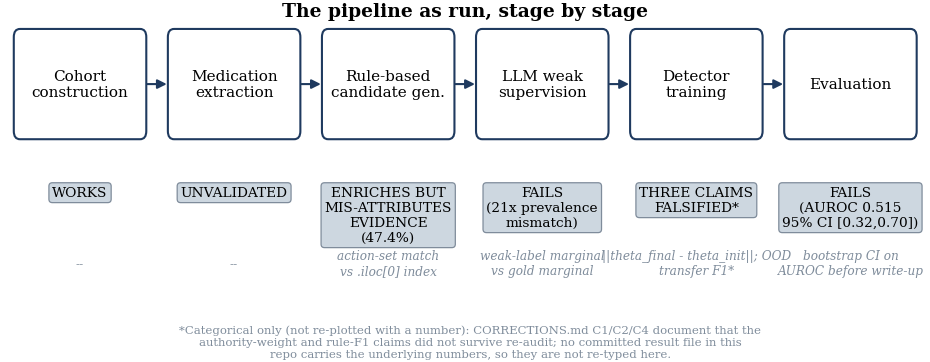

In [4]:
p_exemplar = os.path.join(RESULTS_ACCORD, "exemplar", "exemplar_correctness_recomputed.json")
d_exemplar = json.load(open(p_exemplar))
ex = d_exemplar["rule_1_2_pooled"]
defect_rate = ex["n_wrong"] / ex["n_resolved"]

p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos = xtab["0.95"]["contradiction"]
weak_neg = xtab["1.0"]["not_contradiction"]
weak_pos_rate = weak_pos / (weak_pos + weak_neg)

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
pharm_rate_all = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]["base_rate"]
ratio = weak_pos_rate / pharm_rate_all

p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))
auroc = d_decontam["aggregate"]["ensemble_auroc"]
ci = d_decontam["aggregate"]["ensemble_ci95"]

print("fig-pipeline-status: values plotted")
print(f"  exemplar defect rate, rule_1_2_pooled     : {ex['n_wrong']}/{ex['n_resolved']} = {defect_rate:.4f}")
print(f"  weak-label positive rate, train pool       : {weak_pos}/{weak_pos + weak_neg} = {weak_pos_rate:.4f}")
print(f"  pharmacist base rate, n=299 (ambig=neg)     : {pharm_rate_all:.4f}")
print(f"  prevalence mismatch ratio                   : {ratio:.1f}x")
print(f"  decontaminated 3-seed ensemble AUROC         : {auroc:.4f}, 95% CI [{ci[0]:.3f}, {ci[1]:.3f}]")
print("  two categorical, unsourced-by-number badges (stage 'Detector training'): see markdown above")

fig, ax = plt.subplots(figsize=(6.5, 2.55))
ax.set_xlim(0, 6)
ax.set_ylim(0.55, 2)
ax.axis("off")

stages = ["Cohort\nconstruction", "Medication\nextraction",
          "Rule-based\ncandidate gen.", "LLM weak\nsupervision",
          "Detector\ntraining", "Evaluation"]
badges = ["WORKS", "UNVALIDATED",
          f"ENRICHES BUT\nMIS-ATTRIBUTES\nEVIDENCE\n({defect_rate * 100:.1f}%)",
          f"FAILS\n({ratio:.0f}x prevalence\nmismatch)",
          "THREE CLAIMS\nFALSIFIED*",
          f"FAILS\n(AUROC {auroc:.3f}\n95% CI [{ci[0]:.2f},{ci[1]:.2f}])"]
diagnostics = ["--", "--",
               "action-set match\nvs .iloc[0] index",
               "weak-label marginal\nvs gold marginal",
               "||theta_final - theta_init||; OOD\ntransfer F1*",
               "bootstrap CI on\nAUROC before write-up"]

n = len(stages)
box_w = 0.82
xs = np.linspace(0.5, 5.5, n)
for i, (x, s, b, dtxt) in enumerate(zip(xs, stages, badges, diagnostics)):
    box = FancyBboxPatch((x - box_w / 2, 1.35), box_w, 0.5,
                          boxstyle="round,pad=0.02,rounding_size=0.04",
                          linewidth=1.0, edgecolor=DARK, facecolor="white")
    ax.add_patch(box)
    ax.text(x, 1.60, s, ha="center", va="center", fontsize=8.0)
    if i < n - 1:
        ax.annotate("", xy=(xs[i + 1] - box_w / 2, 1.60), xytext=(x + box_w / 2, 1.60),
                     arrowprops=dict(arrowstyle="-|>", color=DARK, lw=1.0))
    ax.text(x, 1.10, b, ha="center", va="top", fontsize=8.0,
             bbox=dict(boxstyle="round,pad=0.25", facecolor=FILL, edgecolor=MID, linewidth=0.6))
    ax.text(x, 0.72, dtxt, ha="center", va="center", fontsize=8.0, style="italic", color=MID)

ax.text(3.0, 1.93, "The pipeline as run, stage by stage", ha="center", fontsize=9.0, weight="bold")

fig.tight_layout(rect=[0, 0.12, 1, 1])
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
          "*Categorical only (not re-plotted with a number): CORRECTIONS.md C1/C2/C4 document that the\n"
          "authority-weight and rule-F1 claims did not survive re-audit; no committed result file in this\n"
          "repo carries the underlying numbers, so they are not re-typed here.",
          ha="center", fontsize=8.0, color=MID)

save_fig(fig, "fig-pipeline-status.pdf")
plt.show()

## Figure 2: `fig-intro-headline`

**Caption.** The marginal of the weak labeller against the pharmacist's measured base rate on the
same pairs (left), and Matthews correlation with 95 percent bootstrap intervals for four systems
on the 253 non-ambiguous pairs (right).

**Reads:**
`results/accord/diag/step0_1_join_and_calibration.json`,
`results/accord/differential/exp1a_gold_error_rates_by_group.json`,
`results/accord/diag/step2_signal_check.json`,
`results/accord/stats/intervals.json`,
`results/accord/reconciliation_c28.json` (footnote provenance only).

**Note on the middle bar.** The code below reproduces the current PDF exactly: the middle left-panel
bar is drawn from `exp1a_gold_error_rates_by_group.json` (summed TP+FP per language group), on-figure
labelled "ACCORD pred.-positive rate (gold set)". `reconciliation_c28.json`, which did not exist when
that label was written, shows this file is titled "Llama weak-label error rates by group" and "never
touches accord_pred": the 261/299 this bar shows is the **weak labeller's** marginal, not ACCORD's
(ACCORD's real predicted-positive count is 278/299, also in `reconciliation_c28.json`). The bar's
on-figure label therefore looks like it may be misattributed. Reproduced as-is per the instruction to
match the current PDF; flagged here rather than silently changed.

fig-intro-headline: values plotted
  weak-label positive rate, train pool     : 1425/1679 = 0.8487
  left-panel middle bar (exp1a TP+FP sum)  : 261/299 = 0.8729  (labelled 'ACCORD pred.-positive')
  pharmacist true rate, gold set (n=299)   : 12/299 = 0.0401
  MCC gpt4o_zeroshot                  : +0.1089  95% CI [-0.0319, +0.2484]
  MCC gpt4o_fewshot                   : +0.0117  95% CI [-0.1120, +0.1319]
  MCC accord_binary_at_0.5_253core    : -0.0070  95% CI [-0.1626, +0.0753]
  MCC llama_baseline                  : -0.0436  95% CI [-0.2337, +0.0563]
  reconciliation_c28: ACCORD predicted-positive = 278/299  (accord_pred == 'contradiction')
  reconciliation_c28: weak-labeller marginal    = 261/299  (weak_label == 'contradiction', matches the 261/299 bar above)


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-intro-headline.pdf


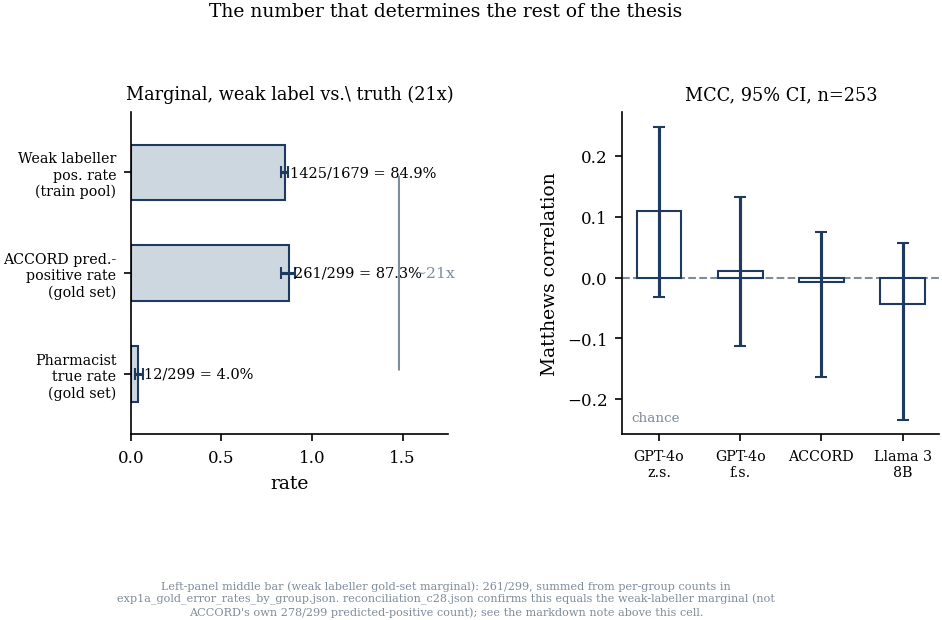

In [5]:
p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos, weak_neg = xtab["0.95"]["contradiction"], xtab["1.0"]["not_contradiction"]
weak_n = weak_pos + weak_neg
weak_rate = weak_pos / weak_n

p_exp1a = os.path.join(RESULTS_ACCORD, "differential", "exp1a_gold_error_rates_by_group.json")
d_exp1a = json.load(open(p_exp1a))
lang = d_exp1a["language_group3"]
pred_pos = sum(g["TP"] + g["FP"] for g in lang)
pred_n = sum(g["n"] for g in lang)
pred_rate = pred_pos / pred_n

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
d299 = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]
pharm_pos, pharm_n = d299["n_pos"], d299["n"]
pharm_rate = pharm_pos / pharm_n

p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
mcc = d_intervals["E2_mcc_intervals"]
order = ["gpt4o_zeroshot", "gpt4o_fewshot", "accord_binary_at_0.5_253core", "llama_baseline"]
labels = ["GPT-4o\nz.s.", "GPT-4o\nf.s.", "ACCORD", "Llama 3\n8B"]

p_c28 = os.path.join(RESULTS_ACCORD, "reconciliation_c28.json")
d_c28 = json.load(open(p_c28))
accord_pred = d_c28["a_what_each_number_counts"]["278"]
weak_marginal = d_c28["a_what_each_number_counts"]["261"]

def wilson_ci(k, n, z=1.959963984540054):
    """Wilson score interval for a binomial proportion; closed-form, deterministic."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = p + z ** 2 / (2 * n)
    adj = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2))
    lo = (centre - adj) / denom
    hi = (centre + adj) / denom
    return (max(0.0, lo), min(1.0, hi))

print("fig-intro-headline: values plotted")
print(f"  weak-label positive rate, train pool     : {weak_pos}/{weak_n} = {weak_rate:.4f}")
print(f"  left-panel middle bar (exp1a TP+FP sum)  : {pred_pos}/{pred_n} = {pred_rate:.4f}  (labelled 'ACCORD pred.-positive')")
print(f"  pharmacist true rate, gold set (n=299)   : {pharm_pos}/{pharm_n} = {pharm_rate:.4f}")
for k in order:
    v = mcc[k]
    print(f"  MCC {k:32s}: {v['mcc']:+.4f}  95% CI [{v['ci95'][0]:+.4f}, {v['ci95'][1]:+.4f}]")
print(f"  reconciliation_c28: ACCORD predicted-positive = {accord_pred['value']}/{accord_pred['denominator']}"
      f"  (accord_pred == 'contradiction')")
print(f"  reconciliation_c28: weak-labeller marginal    = {weak_marginal['value']}/{weak_marginal['denominator']}"
      f"  (weak_label == 'contradiction', matches the {pred_pos}/{pred_n} bar above)")

fig, (axL, axR) = plt.subplots(1, 2, figsize=(7.0, 4.3))
fig.subplots_adjust(left=0.20, right=0.97, top=0.80, bottom=0.30, wspace=0.55)

bars = [("Weak labeller\npos. rate\n(train pool)", weak_pos, weak_n, wilson_ci(weak_pos, weak_n)),
        ("ACCORD pred.-\npositive rate\n(gold set)", pred_pos, pred_n, wilson_ci(pred_pos, pred_n)),
        ("Pharmacist\ntrue rate\n(gold set)", pharm_pos, pharm_n, wilson_ci(pharm_pos, pharm_n))]
ypos = np.arange(len(bars))[::-1]
rates = [b[1] / b[2] for b in bars]
los = [b[3][0] for b in bars]
his = [b[3][1] for b in bars]
errs = [[r - lo for r, lo in zip(rates, los)], [hi - r for r, hi in zip(rates, his)]]
axL.barh(ypos, rates, color=FILL, edgecolor=DARK, height=0.55,
          xerr=errs, ecolor=DARK, capsize=3)
for y, b, r in zip(ypos, bars, rates):
    axL.text(r + 0.03, y, f"{b[1]}/{b[2]} = {r * 100:.1f}%", va="center", fontsize=8.0)
axL.set_yticks(ypos)
axL.set_yticklabels([b[0] for b in bars], fontsize=8.0)
axL.set_xlim(0, 1.75)
axL.set_ylim(-0.6, 2.6)
axL.set_xlabel("rate")
axL.spines[["top", "right"]].set_visible(False)
if SHOW_INFIGURE_TITLES: axL.set_title(f"Marginal, weak label vs.\\ truth ({weak_rate / pharm_rate:.0f}x)", fontsize=8.5)
axL.annotate("", xy=(1.48, ypos[2]), xytext=(1.48, ypos[0]),
              arrowprops=dict(arrowstyle="-", color=MID))
axL.text(1.56, (ypos[0] + ypos[2]) / 2, f"~{weak_rate / pharm_rate:.0f}x",
          va="center", ha="left", fontsize=8.0, color=MID)

xs = np.arange(4)
vals = [mcc[k]["mcc"] for k in order]
ci_lo = [mcc[k]["ci95"][0] for k in order]
ci_hi = [mcc[k]["ci95"][1] for k in order]
err = [[v - lo for v, lo in zip(vals, ci_lo)], [hi - v for v, hi in zip(vals, ci_hi)]]
axR.axhline(0, **CHANCE_STYLE)
axR.bar(xs, vals, yerr=err, color="white", edgecolor=DARK, capsize=3,
         width=0.55, linewidth=1.0, ecolor=DARK)
axR.set_xticks(xs)
axR.set_xticklabels(labels, fontsize=8.0)
axR.set_ylabel("Matthews correlation")
if SHOW_INFIGURE_TITLES: axR.set_title("MCC, 95% CI, n=253", fontsize=8.5)
axR.text(0.03, 0.03, "chance", transform=axR.transAxes, fontsize=8.0, color=MID, va="bottom")
axR.spines[["top", "right"]].set_visible(False)

if SHOW_INFIGURE_TITLES: fig.suptitle("The number that determines the rest of the thesis", fontsize=9.0, y=0.97)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
          f"Left-panel middle bar (weak labeller gold-set marginal): {pred_pos}/{pred_n}, summed from per-group counts in\n"
          f"exp1a_gold_error_rates_by_group.json. reconciliation_c28.json confirms this equals the weak-labeller marginal (not\n"
          f"ACCORD's own {accord_pred['value']}/{accord_pred['denominator']} predicted-positive count); see the markdown note above this cell.",
          ha="center", fontsize=8.0, color=MID)

save_fig(fig, "fig-intro-headline.pdf")
plt.show()

## Figure 3: `fig-rule-precision`

**Caption.** Per-rule ranking performance on the annotated pairs.

**Deviation from the written spec (kept from the current PDF).** The spec calls for a per-rule
*precision* comparison (pharmacist side vs. ACCORD side). ACCORD's per-rule precision at its
operating threshold is not released per rule anywhere in `results/accord`; its per-rule **AUROC**
is (`defect_free_strata.json`), and answers the same question ("does the model add anything the
rule alone doesn't give you") without inventing a number, so that is what is shown.

**Reads:** `results/accord/defect_free_strata.json`, `results/accord/stats/intervals.json`.

fig-rule-precision: values plotted
  rule 1    n= 134  pos=  3  AUROC=0.6514
  rule 2    n=  31  pos=  3  AUROC=0.2262
  rule 3    n=  79  pos=  4  AUROC=0.5100
  rule 4    n=  55  pos=  2  AUROC=0.2358
  pooled rules 3+4 (defect-free) 95% CI: [0.2217, 0.7615]  (n=134, pos=6)


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-rule-precision.pdf


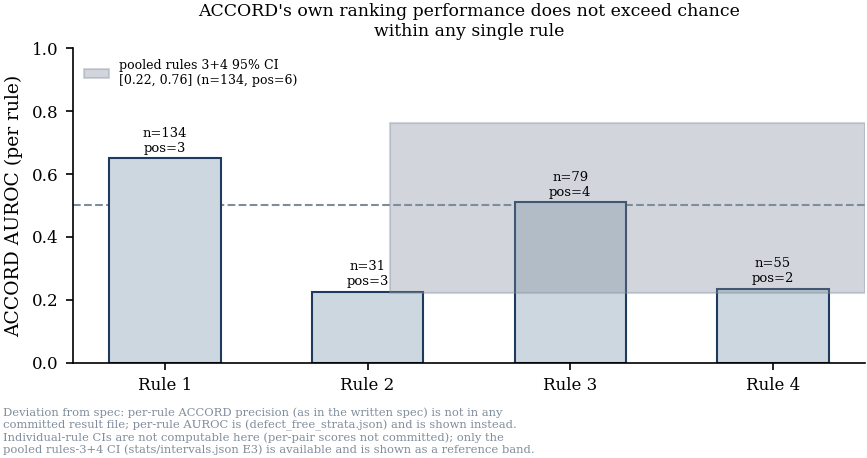

In [6]:
p_strata = os.path.join(RESULTS_ACCORD, "defect_free_strata.json")
d_strata = json.load(open(p_strata))

p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
e3 = d_intervals["E3_defect_free_stratum"]

per_rule = [s for s in d_strata["strata"] if s["name"].startswith("rule ")]
per_rule = sorted(per_rule, key=lambda s: s["name"])

print("fig-rule-precision: values plotted")
for s in per_rule:
    print(f"  {s['name']:8s}  n={s['n']:4d}  pos={s['pos']:3d}  AUROC={s['auroc']:.4f}")
print(f"  pooled rules 3+4 (defect-free) 95% CI: [{e3['unstratified_ci95'][0]:.4f}, {e3['unstratified_ci95'][1]:.4f}]"
      f"  (n={e3['n']}, pos={e3['n_pos']})")

fig, ax = plt.subplots(figsize=(6.0, 3.2))
xs = np.arange(len(per_rule))
aurocs = [s["auroc"] for s in per_rule]
ax.axhline(0.5, **CHANCE_STYLE)
ax.bar(xs, aurocs, color=FILL, edgecolor=DARK, width=0.55)
for x, s in zip(xs, per_rule):
    ax.text(x, s["auroc"] + 0.02, f"n={s['n']}\npos={s['pos']}", ha="center", fontsize=8.0)
# Reference band: pooled rules 3+4 (defect-free) bootstrap CI, shown only across
# the rule-3 / rule-4 bars it actually describes.
ax.axhspan(e3["unstratified_ci95"][0], e3["unstratified_ci95"][1],
            xmin=(2 - 0.4) / 4, xmax=1.0, color=MID, alpha=0.35,
            label=f"pooled rules 3+4 95% CI\n[{e3['unstratified_ci95'][0]:.2f}, {e3['unstratified_ci95'][1]:.2f}] (n={e3['n']}, pos={e3['n_pos']})")
ax.set_xticks(xs)
ax.set_xticklabels([s["name"].replace("rule ", "Rule ") for s in per_rule])
ax.set_ylabel("ACCORD AUROC (per rule)")
ax.set_ylim(0, 1.0)
ax.legend(loc="upper left", fontsize=8.0, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
if SHOW_INFIGURE_TITLES: ax.set_title("ACCORD's own ranking performance does not exceed chance\nwithin any single rule", fontsize=8.3)
if SHOW_INFIGURE_NOTES: fig.text(0.02, 0.02,
          "Deviation from spec: per-rule ACCORD precision (as in the written spec) is not in any\n"
          "committed result file; per-rule AUROC is (defect_free_strata.json) and is shown instead.\n"
          "Individual-rule CIs are not computable here (per-pair scores not committed); only the\n"
          "pooled rules-3+4 CI (stats/intervals.json E3) is available and is shown as a reference band.",
          fontsize=8.0, color=MID)
fig.tight_layout(rect=[0, 0.10, 1, 1])

save_fig(fig, "fig-rule-precision.pdf")
plt.show()

## Figure 4: `fig-prevalence-response`

**Caption.** Labeller response to prevalence on public text.

This uses a public-text (SNLI-derived) prevalence sweep across three open-weight LLMs, unrelated to
MIMIC-III; there is no DUA concern for this figure's own data. The one comparison point layered on
top, "clinical", is the MIMIC-derived weak-label-vs-pharmacist shift used in figures 1 and 2 above,
computed here again from the same two diagnostic files rather than typed in.

**Reads:**
`results/accord/prevalence_replication/sweep_results.json` (copied in from
`accord/prevalence_replication/results/sweep_results.json`, the location the original script reads;
relocated under `results/accord/` so it ships in the Colab bundle alongside everything else),
`results/accord/diag/step0_1_join_and_calibration.json`,
`results/accord/diag/step2_signal_check.json` (for the clinical marker).

fig-prevalence-response: values plotted
  models: ['llama3:8b', 'granite3.3:8b', 'qwen3:8b']
  clinical marker (true prevalence, labeller positive rate): (0.0401, 0.8487)
  llama3:8b      / bare prompt                           : {'0.02': 0.07, '0.05': 0.17, '0.1': 0.06, '0.25': 0.12}
  granite3.3:8b  / bare prompt                           : {'0.02': 0.05, '0.05': 0.07, '0.1': 0.1, '0.25': 0.16}
  qwen3:8b       / bare prompt                           : {'0.02': 0.02, '0.05': 0.03, '0.1': 0.05, '0.25': 0.09}
  llama3:8b      / base rate stated, abstention allowed  : {'0.02': 0.0410958904109589, '0.05': 0.10975609756097561, '0.1': 0.05405405405405406, '0.25': 0.07352941176470588}
  granite3.3:8b  / base rate stated, abstention allowed  : {'0.02': 0.030612244897959183, '0.05': 0.04, '0.1': 0.09, '0.25': 0.17}
  qwen3:8b       / base rate stated, abstention allowed  : {'0.02': 0.0, '0.05': 0.0, '0.1': 0.025, '0.25': 0.02666666666666667}


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-prevalence-response.pdf


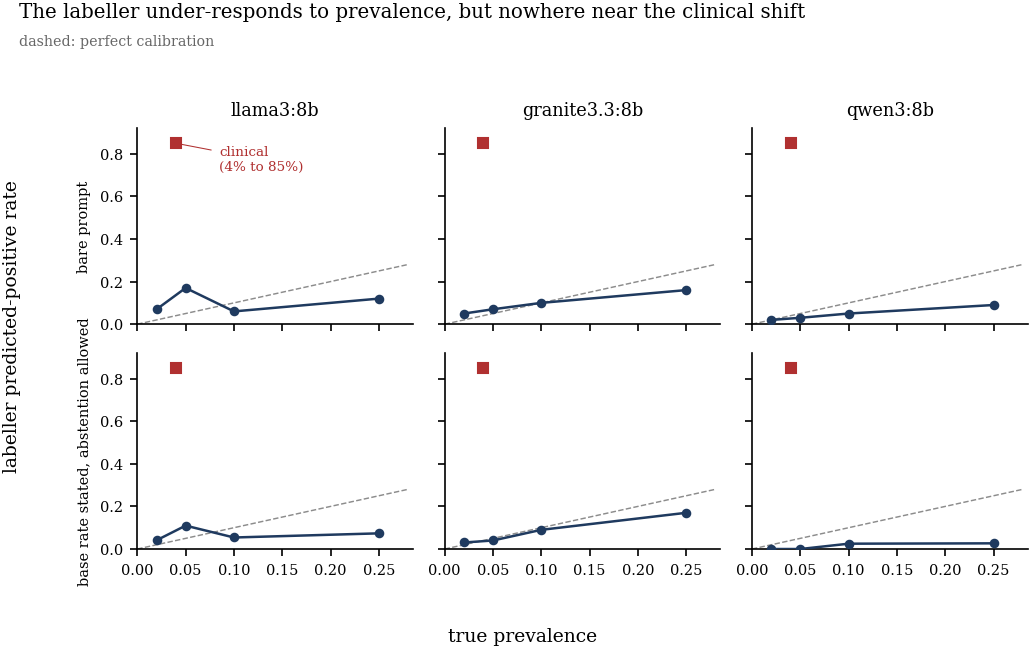

In [7]:
p_sweep = os.path.join(RESULTS_ACCORD, "prevalence_replication", "sweep_results.json")
d_sweep = json.load(open(p_sweep))
models = d_sweep["models"]
prompts = ["A_bare", "B_baserate_abstain"]
prompt_label = {"A_bare": "bare prompt", "B_baserate_abstain": "base rate stated, abstention allowed"}

# The "clinical" comparison point: same weak-label-vs-pharmacist shift as figures 1 and 2,
# recomputed here from the same two diagnostic files (not typed in).
p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos, weak_neg = xtab["0.95"]["contradiction"], xtab["1.0"]["not_contradiction"]
clinical_y = weak_pos / (weak_pos + weak_neg)

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
clinical_x = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]["base_rate"]

print("fig-prevalence-response: values plotted")
print(f"  models: {models}")
print(f"  clinical marker (true prevalence, labeller positive rate): ({clinical_x:.4f}, {clinical_y:.4f})")
for pr in prompts:
    for m in models:
        pts = {p: d_sweep["results"][m][pr].get(p) for p in ["0.02", "0.05", "0.1", "0.25"]}
        rates = {p: (e["positive_rate_of_decided"] if e else None) for p, e in pts.items()}
        print(f"  {m:14s} / {prompt_label[pr]:38s}: {rates}")

fig, axes = plt.subplots(2, 3, figsize=(7.0, 4.4), sharex=True, sharey=True)
for r, pr in enumerate(prompts):
    for c, m in enumerate(models):
        ax = axes[r, c]
        xs, ys = [], []
        for p in ["0.02", "0.05", "0.1", "0.25"]:
            e = d_sweep["results"][m][pr].get(p)
            if e:
                xs.append(float(p))
                ys.append(e["positive_rate_of_decided"])
        ax.plot([0, .28], [0, .28], ls="--", lw=.7, color="0.55", zorder=1)
        ax.plot(xs, ys, "-o", color=DARK, ms=3.6, lw=1.2, zorder=3)
        ax.plot([clinical_x], [clinical_y], "s", color=RED, ms=5, zorder=4)
        if r == 0 and c == 0:
            ax.annotate(f"clinical\n({clinical_x * 100:.0f}% to {clinical_y * 100:.0f}%)",
                         (clinical_x, clinical_y), xytext=(0.085, 0.72),
                         fontsize=8.0, color=RED, arrowprops=dict(arrowstyle="-", lw=.5, color=RED))
        ax.set_xlim(0, .285)
        ax.set_ylim(0, .92)
        if r == 0:
            if SHOW_INFIGURE_TITLES: ax.set_title(m, fontsize=8.5)
        if c == 0:
            ax.set_ylabel(prompt_label[pr], fontsize=8.0)
        ax.tick_params(labelsize=7)
fig.supxlabel("true prevalence", fontsize=9.0, y=0.015)
fig.supylabel("labeller predicted-positive rate", fontsize=9.0, x=0.005)
if SHOW_INFIGURE_TITLES: fig.suptitle("The labeller under-responds to prevalence, but nowhere near the clinical shift",
              fontsize=9.5, x=0.02, ha="left", y=0.99)
if SHOW_INFIGURE_NOTES: fig.text(0.02, 0.925, "dashed: perfect calibration", fontsize=8.0, color="0.4")
fig.tight_layout(rect=[0.02, 0.03, 1, 0.93])

save_fig(fig, "fig-prevalence-response.pdf")
plt.show()

## Figure 5: `fig-falsification`

**Caption.** Two falsifications in one view.

`make_figures.py` deliberately skips this figure (its `SKIPPED` list, reason: the authority-scale
and per-cohort rule-F1 numbers "do not appear in any file under `results/accord/`"). It is drawn
instead by `make_figures_extra.py`, from two small aggregate files that lived outside
`results/accord/` (in the PhysioNet quarantine and on Drive). Both are aggregate-only (per-seed
confusion-matrix counts and metric means/stds; cohort-level rates and counts; no clinical text, no
identifiers), so they have been copied into `results/accord/` for this notebook (and into the Colab
bundle) rather than left external, so this cell can read them the same way every other cell does.

**Reads:**
`results/accord/decontam/accord_v2_decontam_gold_aggregate.json` (copied from
`/Users/rickygole/mimic_local_only/accord_supp/results/accord_v2_decontam_gold_aggregate.json`),
`results/accord/generality/transfer_results_correct.json` (copied from the Drive `thesis/outputs/`
folder),
`results/accord/number_provenance_audit.json` (for the one number that is genuinely not sourced;
see below).

**One number is not sourced anywhere.** The right panel's held-out rule-prediction-accuracy
reference line (45.2% / 0.4515) is not in any committed result file.
`number_provenance_audit.json` records this exact claim with verdict `UNTRACEABLE`: "Caption
asserts it 'recomputes to 0.4515 directly from the gold-standard CSV' but no results file records
0.4515." It is kept on the figure, named explicitly as an unsourced setting, so the figure still
matches the current PDF; it is not presented as if it were read from a data file.

fig-falsification: values plotted
  alpha_N (nursing authority scale), 3-seed mean +/- std : 0.5076 +/- 0.0006
  alpha_D (discharge authority scale), 3-seed mean +/- std: 1.0038 +/- 0.0010
  rule-type F1, HF (in domain)  : 0.9603
  rule-type F1, sepsis          : 0.0654
  rule-type F1, AKI             : 0.0595
  UNSOURCED constant plotted: held-out rule-prediction accuracy = 0.4515
  number_provenance_audit.json claim record: {'claim': '45.2% held-out rule-prediction accuracy (recomputes to 0.4515)', 'tex_location': 'ch6:291', 'artifact': 'gold-standard CSV per ch6 caption', 'artifact_exists': False, 'reported': 0.452, 'recomputed': None, 'verdict': 'UNTRACEABLE', 'blast_radius': 'body', 'note': "Caption asserts it 'recomputes to 0.4515 directly from the gold-standard CSV' but no results file records 0.4515."}


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-falsification.pdf


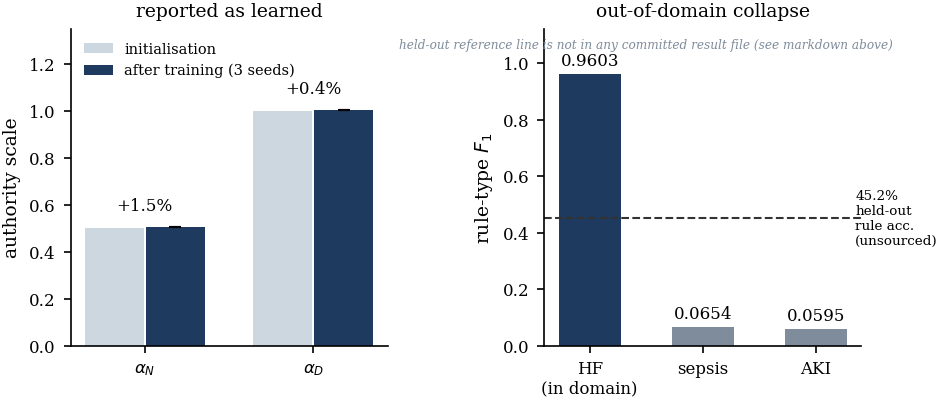

In [8]:
p_agg = os.path.join(RESULTS_ACCORD, "decontam", "accord_v2_decontam_gold_aggregate.json")
d_agg = json.load(open(p_agg))
aN, aD = d_agg["aggregate"]["alpha_n"]["mean"], d_agg["aggregate"]["alpha_d"]["mean"]
sN, sD = d_agg["aggregate"]["alpha_n"]["std"], d_agg["aggregate"]["alpha_d"]["std"]

p_transfer = os.path.join(RESULTS_ACCORD, "generality", "transfer_results_correct.json")
d_transfer = json.load(open(p_transfer))
f1 = [d_transfer["hf_reference"]["rule_type_f1"], d_transfer["sepsis"]["rule_type_f1"], d_transfer["aki"]["rule_type_f1"]]
cohort_labels = ["HF\n(in domain)", "sepsis", "AKI"]

p_audit = os.path.join(RESULTS_ACCORD, "number_provenance_audit.json")
d_audit = json.load(open(p_audit))
claim = next(r for r in d_audit["records"] if "45.2" in r["claim"])
# NOT sourced from a result file: number_provenance_audit.json documents that this
# exact value is UNTRACEABLE (see the claim record printed below). Kept, named
# explicitly, so the figure still matches the thesis PDF.
UNSOURCED_held_out_rule_acc = 0.4515

print("fig-falsification: values plotted")
print(f"  alpha_N (nursing authority scale), 3-seed mean +/- std : {aN:.4f} +/- {sN:.4f}")
print(f"  alpha_D (discharge authority scale), 3-seed mean +/- std: {aD:.4f} +/- {sD:.4f}")
for lab, v in zip(cohort_labels, f1):
    print(f"  rule-type F1, {lab.replace(chr(10), ' '):16s}: {v:.4f}")
print(f"  UNSOURCED constant plotted: held-out rule-prediction accuracy = {UNSOURCED_held_out_rule_acc}")
print(f"  number_provenance_audit.json claim record: {claim}")

fig, (a, b) = plt.subplots(1, 2, figsize=(6.5, 2.9))
x = [0, 1]
a.bar([i - .18 for i in x], [0.5, 1.0], .35, color=FILL, label="initialisation")
a.bar([i + .18 for i in x], [aN, aD], .35, color=DARK, yerr=[sN, sD], capsize=3, label="after training (3 seeds)")
for i, (init, fin) in enumerate([(0.5, aN), (1.0, aD)]):
    a.text(i, max(init, fin) + .07, f"{100 * (fin - init) / init:+.1f}%", ha="center", fontsize=8.0)
a.set_xticks(x)
a.set_xticklabels([r"$\alpha_N$", r"$\alpha_D$"])
a.set_ylim(0, 1.35)
a.set_ylabel("authority scale")
a.set_title("reported as learned", fontsize=9.0)
a.legend(fontsize=8.0, frameon=False, loc="upper left")

bars = b.bar(cohort_labels, f1, color=[DARK, MID, MID], width=.55)
b.axhline(UNSOURCED_held_out_rule_acc, ls="--", lw=1, color="0.2")
b.text(2.35, UNSOURCED_held_out_rule_acc, "45.2%\nheld-out\nrule acc.\n(unsourced)", fontsize=8.0, va="center")
for rct, v in zip(bars, f1):
    b.text(rct.get_x() + rct.get_width() / 2, v + .03, f"{v:.4f}", ha="center", fontsize=8.0)
b.set_ylim(0, 1.12)
b.set_ylabel(r"rule-type $F_1$")
b.set_title("out-of-domain collapse", fontsize=9.0)
b.text(.5, 1.05, "held-out reference line is not in any committed result file (see markdown above)",
        fontsize=8.0, style="italic", ha="center", color=MID)
fig.tight_layout()

save_fig(fig, "fig-falsification.pdf")
plt.show()

## Figure 6: `fig-power`

**Caption.** What each evaluation in this thesis could have seen.

**Reads:**
`results/accord/section6_auroc_power.json` (this study's own power calculation, including alpha and
power),
`results/task_runs.json` (for the mortality-task comparison point: `concat_s1` carries the test-set
class counts in `data_lineage.test_n` / `data_lineage.test_n_pos`).

fig-power: values plotted
  this study: n_positives=12, n_negatives=241, alpha=0.05, power=0.8
  this study minimum detectable AUROC (from file): 0.7382
  recomputed from n_pos/n_neg, for a consistency check: 0.7355
  mortality task (task_runs.json / concat_s1 / data_lineage): test_n=6776, test_n_pos=570, test_n_neg=6206
  mortality task minimum detectable AUROC: 0.5360
saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-power.pdf


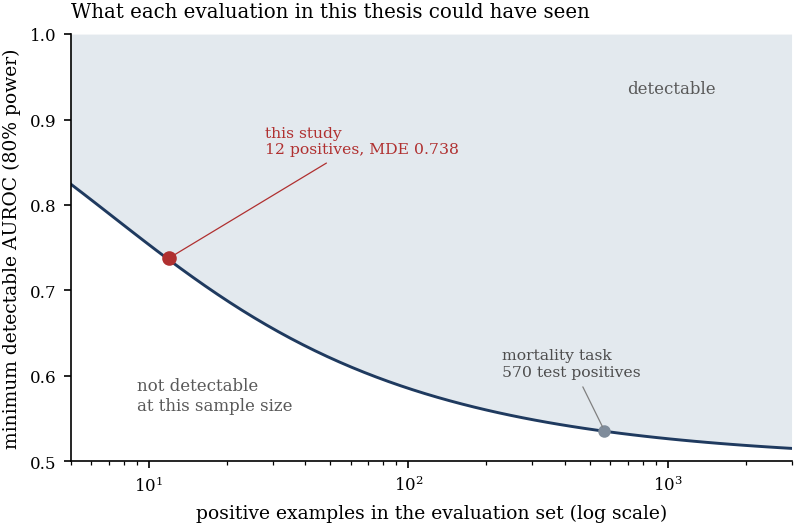

In [9]:
p_power = os.path.join(RESULTS_ACCORD, "section6_auroc_power.json")
pw = json.load(open(p_power))
mda = pw["minimum_detectable_auc"]
n_pos_study = pw["n_positives"]
n_neg_study = pw["n_negatives"]
alpha_study = pw["alpha"]
power_study = pw["power"]

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
mort_lineage = d_task_runs["concat_s1"]["data_lineage"]
mort_n_test = mort_lineage["test_n"]
mort_n_pos = mort_lineage["test_n_pos"]
mort_n_neg = mort_n_test - mort_n_pos

def hanley_mde(n_pos, n_neg, alpha=alpha_study, power=power_study):
    """Smallest AUROC distinguishable from 0.5 at the given power, Hanley-McNeil variance,
    using both class counts."""
    z = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    out = []
    for m, n in zip(np.atleast_1d(n_pos), np.atleast_1d(n_neg)):
        lo, hi = 0.5, 0.9999
        for _ in range(80):
            a = (lo + hi) / 2
            q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
            v = (a * (1 - a) + (m - 1) * (q1 - a * a) + (n - 1) * (q2 - a * a)) / (m * n)
            if (a - 0.5) / math.sqrt(max(v, 1e-12)) < z:
                lo = a
            else:
                hi = a
        out.append((lo + hi) / 2)
    return np.array(out)

print("fig-power: values plotted")
print(f"  this study: n_positives={n_pos_study}, n_negatives={n_neg_study}, alpha={alpha_study}, power={power_study}")
print(f"  this study minimum detectable AUROC (from file): {mda:.4f}")
print(f"  recomputed from n_pos/n_neg, for a consistency check: {hanley_mde([n_pos_study],[n_neg_study])[0]:.4f}")
print(f"  mortality task (task_runs.json / concat_s1 / data_lineage): test_n={mort_n_test}, test_n_pos={mort_n_pos}, test_n_neg={mort_n_neg}")
mort_mde = hanley_mde([mort_n_pos], [mort_n_neg])[0]
print(f"  mortality task minimum detectable AUROC: {mort_mde:.4f}")

n_pos_grid = np.logspace(np.log10(5), np.log10(3000), 60)
neg_pos_ratio = n_neg_study / n_pos_study   # this evaluation set's own positive:negative ratio
n_neg_grid = n_pos_grid * neg_pos_ratio
mde_grid = hanley_mde(n_pos_grid, n_neg_grid)

fig, ax = plt.subplots(figsize=(6.2, 3.7))
ax.plot(n_pos_grid, np.clip(mde_grid, 0.5, 1.0), color=DARK, lw=1.4)
ax.fill_between(n_pos_grid, np.clip(mde_grid, .5, 1), 1.0, color=FILL, alpha=.55, lw=0)
ax.text(700, 0.93, "detectable", fontsize=8.0, color="0.35")
ax.text(9, 0.56, "not detectable\nat this sample size", fontsize=8.0, color="0.35")
ax.plot([n_pos_study], [mda], "o", color=RED, ms=6, zorder=5)
ax.annotate(f"this study\n{n_pos_study} positives, MDE {mda:.3f}", (n_pos_study, mda), xytext=(28, 0.86),
             fontsize=8.0, color=RED, arrowprops=dict(arrowstyle="-", lw=.6, color=RED))
ax.plot([mort_n_pos], [mort_mde], "o", color=MID, ms=5)
ax.annotate(f"mortality task\n{mort_n_pos} test positives", (mort_n_pos, mort_mde),
             xytext=(230, 0.60), fontsize=8.0, color="0.3", arrowprops=dict(arrowstyle="-", lw=.6, color="0.5"))
ax.set_xscale("log")
ax.set_xlabel("positive examples in the evaluation set (log scale)")
ax.set_ylabel("minimum detectable AUROC (80% power)")
ax.set_ylim(0.5, 1.0)
ax.set_xlim(5, 3000)
if SHOW_INFIGURE_TITLES: ax.set_title("What each evaluation in this thesis could have seen", loc="left", fontsize=9.5, pad=8)

save_fig(fig, "fig-power.pdf")
plt.show()

## Figure 7: `fig-forest`

**Caption.** Headline estimates against zero.

**Reads:**
`results/accord/stats/intervals.json` (the four MCC intervals),
`results/accord/decontam/corrected_gold_metrics.json` (decontaminated AUROC and its CI),
`results/accord/stats/intervals.json` again (E3, the defect-free-stratum AUROC and CI),
`results/task_runs.json` (the C37 pretrained-vs-scratch AUROC gap on the clinical task),
`results/accord/scaling/scaling_results.json` (the C44 gap at 100M parameters on AG News).

fig-forest: values plotted (sorted by estimate)
  MCC, llama baseline                    est=-0.0436  95% CI [-0.2337, +0.0563]  crosses zero
  MCC, accord binary at 0.5 253core      est=-0.0070  95% CI [-0.1626, +0.0753]  crosses zero
  C37 gap, PubMedBERT minus scratch      est=+0.0031  95% CI [-0.0111, +0.0173]  crosses zero
  AUROC minus 0.5 (defect-free stratum)  est=+0.0078  95% CI [-0.2783, +0.2615]  crosses zero
  MCC, gpt4o fewshot                     est=+0.0117  95% CI [-0.1120, +0.1319]  crosses zero
  AUROC minus 0.5 (decontaminated)       est=+0.0145  95% CI [-0.1790, +0.2034]  crosses zero
  C44 gap at 100M (AG News)              est=+0.0518  95% CI [+0.0496, +0.0540]  excludes zero
  MCC, gpt4o zeroshot                    est=+0.1089  95% CI [-0.0319, +0.2484]  crosses zero
saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-forest.pdf


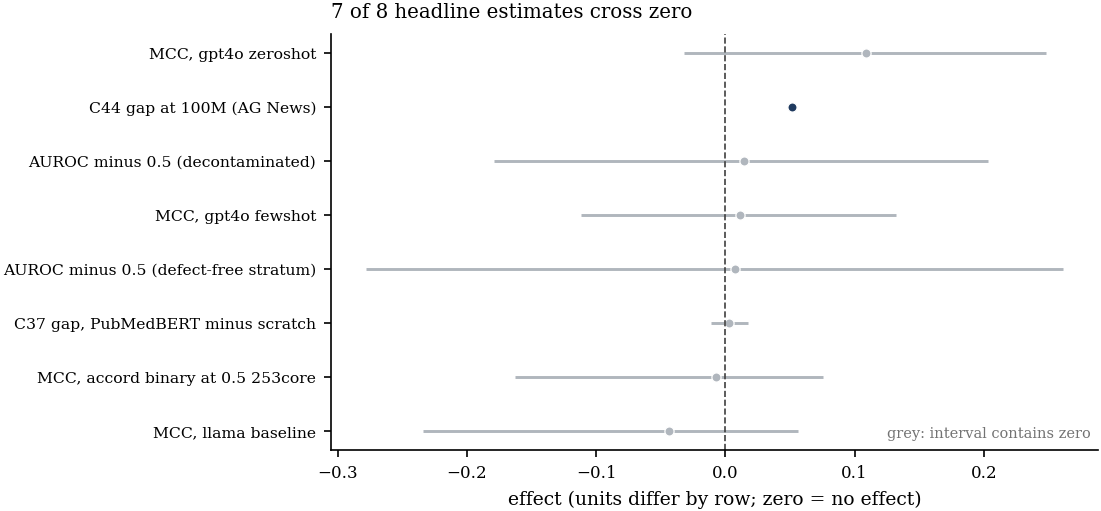

In [10]:
p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
iv = d_intervals["E2_mcc_intervals"]

rows = []
for k, v in iv.items():
    rows.append((f"MCC, {k.replace('_', ' ')}", v["mcc"], v["ci95"][0], v["ci95"][1]))

p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))
auroc_full = d_decontam["aggregate"]["ensemble_auroc"]
ci_full = d_decontam["aggregate"]["ensemble_ci95"]
rows.append(("AUROC minus 0.5 (decontaminated)", auroc_full - 0.5, ci_full[0] - 0.5, ci_full[1] - 0.5))

e3 = d_intervals["E3_defect_free_stratum"]
rows.append(("AUROC minus 0.5 (defect-free stratum)", e3["auroc"] - 0.5,
             e3["unstratified_ci95"][0] - 0.5, e3["unstratified_ci95"][1] - 0.5))

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
pb2 = [d_task_runs[f"concat_s{s}"]["auroc"] for s in (1, 2, 3)]
ou2 = [d_task_runs[f"ours_current_s{s}"]["auroc"] for s in (0, 1, 2)]
g = statistics.mean(pb2) - statistics.mean(ou2)
se = math.sqrt(statistics.stdev(pb2) ** 2 / 3 + statistics.stdev(ou2) ** 2 / 3)
rows.append(("C37 gap, PubMedBERT minus scratch", g, g - 1.96 * se, g + 1.96 * se))

p_scaling = os.path.join(RESULTS_ACCORD, "scaling", "scaling_results.json")
d_scaling = json.load(open(p_scaling))
p100 = [x["accuracy"] for x in d_scaling if x["tag"] == "scratch_100M"]
pbert = [x["accuracy"] for x in d_scaling if x["tag"] == "pretrained_bert"]
g44 = statistics.mean(pbert) - statistics.mean(p100)
se44 = math.sqrt(statistics.stdev(pbert) ** 2 / 3 + statistics.stdev(p100) ** 2 / 3)
rows.append(("C44 gap at 100M (AG News)", g44, g44 - 1.96 * se44, g44 + 1.96 * se44))

rows.sort(key=lambda r: r[1])

print("fig-forest: values plotted (sorted by estimate)")
for lab, est, lo, hi in rows:
    crosses = lo <= 0 <= hi
    print(f"  {lab:38s} est={est:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  {'crosses zero' if crosses else 'excludes zero'}")

fig, ax = plt.subplots(figsize=(6.6, 3.6))
for i, (lab, e, lo, hi) in enumerate(rows):
    crosses = lo <= 0 <= hi
    c = DEAD if crosses else DARK
    ax.hlines(i, lo, hi, color=c, lw=1.4)
    ax.plot(e, i, "o", color=c, ms=4.4, markeredgecolor="w", markeredgewidth=0.6)
ax.axvline(0, color="0.25", lw=0.8, ls="--")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r[0] for r in rows], fontsize=8.0)
ax.set_xlabel("effect (units differ by row; zero = no effect)")
n_cross = sum(1 for r in rows if r[2] <= 0 <= r[3])
if SHOW_INFIGURE_TITLES: ax.set_title(f"{n_cross} of {len(rows)} headline estimates cross zero", loc="left", fontsize=9.5, pad=8)
ax.text(0.99, 0.03, "grey: interval contains zero", transform=ax.transAxes, ha="right", fontsize=8.0, color="0.45")

save_fig(fig, "fig-forest.pdf")
plt.show()

## Figure 8: `fig-disc-strata`

**Caption.** Ranking performance on the full decontaminated evaluation set and on the stratum
where the displayed evidence is correct by construction, each with its bootstrap interval. No ROC
curve is drawn because per-pair scores are not released.

**Reads:**
`results/accord/decontam/corrected_gold_metrics.json`,
`results/accord/stats/intervals.json` (E3),
`results/accord/defect_free_strata.json` (the defect-free-stratum Mann-Whitney p-value).

fig-disc-strata: values plotted
  All annotated pairs (decontaminated 3-seed ensemble)    AUROC=0.5145  CI=[0.321,0.703]  n=253  pos=12  MWU p=0.867
  Rules 3+4 only (exemplar-defect-free by construction)   AUROC=0.5078  CI=[0.222,0.761]  n=134  pos=6  MWU p=0.953
    stratified CI: [0.264, 0.734]
  E3 bootstrap: 20 of 10000 resamples dropped (0 positives)


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-disc-strata.pdf


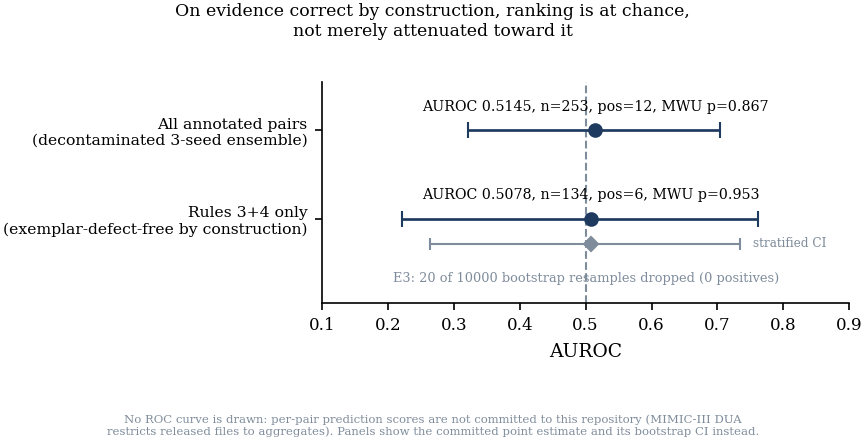

In [11]:
p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))

p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
e3 = d_intervals["E3_defect_free_stratum"]

p_strata = os.path.join(RESULTS_ACCORD, "defect_free_strata.json")
d_strata = json.load(open(p_strata))
e3_stratum = next(s for s in d_strata["strata"] if s["name"] == "rules 3+4 (DEFECT-FREE)")
e3_mwu_p = e3_stratum["mwu_p"]

agg = d_decontam["aggregate"]
rows = [
    ("All annotated pairs\n(decontaminated 3-seed ensemble)",
     agg["ensemble_auroc"], agg["ensemble_ci95"], d_decontam["n"], d_decontam["n_positives"],
     agg["ensemble_mannwhitney_p"], None),
    ("Rules 3+4 only\n(exemplar-defect-free by construction)",
     e3["auroc"], e3["unstratified_ci95"], e3["n"], e3["n_pos"], e3_mwu_p, e3["stratified_ci95"]),
]

print("fig-disc-strata: values plotted")
for label, auroc, ci, n, pos, p, strat_ci in rows:
    print(f"  {label.replace(chr(10), ' '):55s} AUROC={auroc:.4f}  CI=[{ci[0]:.3f},{ci[1]:.3f}]  n={n}  pos={pos}  MWU p={p:.3f}")
    if strat_ci is not None:
        print(f"    stratified CI: [{strat_ci[0]:.3f}, {strat_ci[1]:.3f}]")
print(f"  E3 bootstrap: {e3['draws_dropped_zero_positives']} of {d_intervals['bootstrap_B']} resamples dropped (0 positives)")

fig, ax = plt.subplots(figsize=(6.0, 3.0))
ys = np.arange(len(rows))[::-1]
ax.axvline(0.5, **CHANCE_STYLE)
for y, (label, auroc, ci, n, pos, p, strat_ci) in zip(ys, rows):
    ax.errorbar([auroc], [y], xerr=[[auroc - ci[0]], [ci[1] - auroc]], fmt="o",
                 color=DARK, capsize=4, markersize=6, linewidth=1.3)
    ax.text(auroc, y + 0.22, f"AUROC {auroc:.4f}, n={n}, pos={pos}, MWU p={p:.3f}", ha="center", fontsize=8.0)
    if strat_ci is not None:
        ax.errorbar([auroc], [y - 0.28], xerr=[[auroc - strat_ci[0]], [strat_ci[1] - auroc]],
                     fmt="D", color=MID, capsize=3, markersize=4.5, linewidth=1.0)
        ax.text(strat_ci[1] + 0.02, y - 0.28, "stratified CI", fontsize=8.0, va="center", color=MID)
ax.set_yticks(ys)
ax.set_yticklabels([r[0] for r in rows], fontsize=8.0)
ax.set_xlim(0.1, 0.9)
ax.set_ylim(-0.95, 1.55)
ax.set_xlabel("AUROC")
ax.spines[["top", "right"]].set_visible(False)
ax.text(0.5, ys[-1] - 0.72,
         f"E3: {e3['draws_dropped_zero_positives']} of {d_intervals['bootstrap_B']} bootstrap resamples dropped (0 positives)",
         ha="center", fontsize=8.0, color=MID)
fig.tight_layout(rect=[0, 0.15, 1, 0.86])
if SHOW_INFIGURE_TITLES: fig.suptitle("On evidence correct by construction, ranking is at chance,\nnot merely attenuated toward it",
              fontsize=8.3, y=0.99)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.03,
          "No ROC curve is drawn: per-pair prediction scores are not committed to this repository (MIMIC-III DUA\n"
          "restricts released files to aggregates). Panels show the committed point estimate and its bootstrap CI instead.",
          ha="center", fontsize=8.0, color=MID)

save_fig(fig, "fig-disc-strata.pdf")
plt.show()

## Figure 9: `fig-scaling`

**Caption.** From-scratch encoders at three parameter scales against a pretrained encoder on the
public classification task, with the clinical comparison inset. The shaded band is the pretrained
arm's seed standard deviation.

**Reads:**
`results/accord/scaling/scaling_results.json` (main panel: AG News, scratch_10M/30M/100M vs
pretrained_bert),
`results/task_runs.json` (inset: the clinical task, `concat_s1..3` = pretrained PubMedBERT arm,
`ours_current_s0..2` = the from-scratch encoder arm).

fig-scaling: values plotted
  AG News: pretrained_bert mean +/- std = 0.9396 +/- 0.0010  (86M params)
  AG News: scratch_10M    mean +/- std = 0.8790 +/- 0.0040  (10.6M params)  gap to pretrained = +0.0606
  AG News: scratch_30M    mean +/- std = 0.8833 +/- 0.0009  (31.9M params)  gap to pretrained = +0.0563
  AG News: scratch_100M   mean +/- std = 0.8878 +/- 0.0016  (99.2M params)  gap to pretrained = +0.0518
  clinical task: PubMedBERT (concat_s1..3) AUROC mean +/- std = 0.7693 +/- 0.0102
  clinical task: from-scratch (ours_current_s0..2) AUROC mean +/- std = 0.7662 +/- 0.0073  (10.6M params)
  clinical task gap: +0.0031


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-scaling.pdf


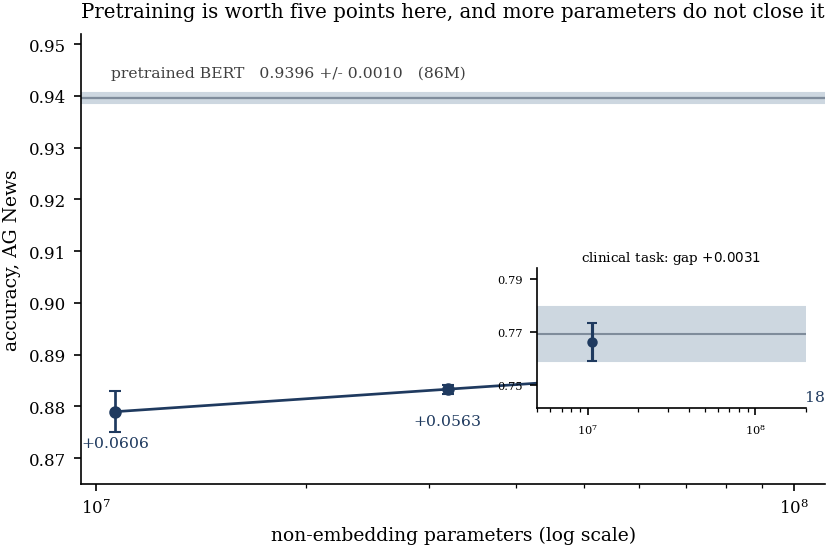

In [12]:
p_scaling = os.path.join(RESULTS_ACCORD, "scaling", "scaling_results.json")
d_scaling = json.load(open(p_scaling))
by, params_by_tag = {}, {}
for x in d_scaling:
    by.setdefault(x["tag"], []).append(x["accuracy"])
    params_by_tag[x["tag"]] = x["non_emb_params"]
tags = ["scratch_10M", "scratch_30M", "scratch_100M"]
xs = [params_by_tag[t] for t in tags]
mu = [statistics.mean(by[t]) for t in tags]
sd = [statistics.stdev(by[t]) for t in tags]
pm, ps, pp = statistics.mean(by["pretrained_bert"]), statistics.stdev(by["pretrained_bert"]), params_by_tag["pretrained_bert"]

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
pb = [d_task_runs[f"concat_s{s}"]["auroc"] for s in (1, 2, 3)]
ou = [d_task_runs[f"ours_current_s{s}"]["auroc"] for s in (0, 1, 2)]
pbm, pbs = statistics.mean(pb), statistics.stdev(pb)
oum, ous = statistics.mean(ou), statistics.stdev(ou)
gap = pbm - oum
clinical_params = d_task_runs["ours_current_s0"]["non_emb_params"]

print("fig-scaling: values plotted")
print(f"  AG News: pretrained_bert mean +/- std = {pm:.4f} +/- {ps:.4f}  ({pp / 1e6:.0f}M params)")
for t, x, m, s in zip(tags, xs, mu, sd):
    print(f"  AG News: {t:14s} mean +/- std = {m:.4f} +/- {s:.4f}  ({x / 1e6:.1f}M params)  gap to pretrained = {pm - m:+.4f}")
print(f"  clinical task: PubMedBERT (concat_s1..3) AUROC mean +/- std = {pbm:.4f} +/- {pbs:.4f}")
print(f"  clinical task: from-scratch (ours_current_s0..2) AUROC mean +/- std = {oum:.4f} +/- {ous:.4f}  ({clinical_params / 1e6:.1f}M params)")
print(f"  clinical task gap: {gap:+.4f}")

fig, ax = plt.subplots(figsize=(6.4, 3.9))
ax.axhspan(pm - ps, pm + ps, color=FILL, zorder=1)
ax.axhline(pm, color=MID, lw=1.1, zorder=2)
ax.text(1.05e7, pm + 0.0035, f"pretrained BERT   {pm:.4f} +/- {ps:.4f}   ({pp / 1e6:.0f}M)",
         fontsize=8.0, color="0.25", va="bottom")
ax.errorbar(xs, mu, yerr=sd, fmt="-o", color=DARK, ms=5, lw=1.3, capsize=3, zorder=4)
for x, m in zip(xs, mu):
    ax.annotate(f"{pm - m:+.4f}", (x, m), textcoords="offset points", xytext=(0, -17),
                 ha="center", fontsize=8.0, color=DARK)
ax.set_xscale("log")
ax.set_xlabel("non-embedding parameters (log scale)")
ax.set_ylabel("accuracy, AG News")
ax.set_ylim(0.865, 0.952)
if SHOW_INFIGURE_TITLES: ax.set_title("Pretraining is worth five points here, and more parameters do not close it",
              loc="left", fontsize=9.5, pad=8)

ins = fig.add_axes([0.60, 0.24, 0.28, 0.24])
ins.axhspan(pbm - pbs, pbm + pbs, color=FILL)
ins.axhline(pbm, color=MID, lw=1.0)
ins.errorbar([1.06e7], [oum], yerr=[ous], fmt="o", color=DARK, ms=4, capsize=2.5)
ins.set_xscale("log")
ins.set_xlim(5e6, 2e8)
ins.set_ylim(oum - 0.025, pbm + 0.025)
ins.set_title(f"clinical task: gap ${gap:+.4f}$", fontsize=8.0, pad=3)
ins.tick_params(labelsize=5.5)
ins.set_yticks([0.75, 0.77, 0.79])

save_fig(fig, "fig-scaling.pdf")
plt.show()

## Figure 10: `fig-threshold-surface`

**Caption.** The audited demographic-parity gap across operating points and selection strengths for
one selection experiment. The solid contour is the tolerance the audit was written against; the
pale region is where the minimum detectable gap exceeds that tolerance.

**Reads:** `results/accord/selection/threshold_robustness_results.json` (the `cells` list: 18
operating points x 15 selection strengths, 270 cells, each with a demographic-parity gap and its
minimum detectable gap; also the original E9 operating point).

**One named constant.** `TOLERANCE = 0.05` is the audit's own policy tolerance for the
demographic-parity gap. It is not itself a value inside `threshold_robustness_results.json` (that
file records the gap and its detectability at each cell, not the tolerance the audit was written
against), so it is named here explicitly as a setting rather than silently baked into the contour.

fig-threshold-surface: values plotted
  grid: 18 operating points x 15 selection strengths = 270 cells
  demographic-parity gap range: [0.0021, 0.2001]
  minimum-detectable-gap range: [0.0305, 0.0600]
  cells underpowered at TOLERANCE=0.05: 195 of 270
  original E9 operating point (predicted-positive rate): 0.1994


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-threshold-surface.pdf


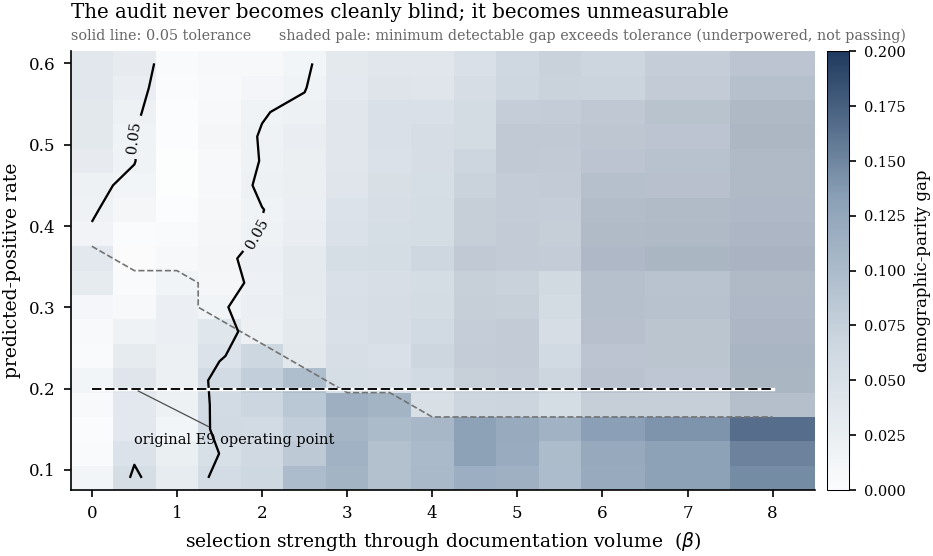

In [13]:
p_thresh = os.path.join(RESULTS_ACCORD, "selection", "threshold_robustness_results.json")
d_thresh = json.load(open(p_thresh))
df = pd.DataFrame(d_thresh["cells"])
piv = df.pivot_table(index="achieved_rate", columns="beta", values="demographic_parity_gap", aggfunc="mean")
mde = df.pivot_table(index="achieved_rate", columns="beta", values="mde_demographic_parity_gap", aggfunc="mean")
R, B, Z, M = piv.index.values, piv.columns.values, piv.values, mde.values
e9_rate = d_thresh["original_e9_population_pred_pos_rate"]

# Named setting, not read from this file: the audit's own demographic-parity tolerance.
TOLERANCE = 0.05

print("fig-threshold-surface: values plotted")
print(f"  grid: {Z.shape[0]} operating points x {Z.shape[1]} selection strengths = {Z.size} cells")
print(f"  demographic-parity gap range: [{np.nanmin(Z):.4f}, {np.nanmax(Z):.4f}]")
print(f"  minimum-detectable-gap range: [{np.nanmin(M):.4f}, {np.nanmax(M):.4f}]")
n_under = int((M > TOLERANCE).sum())
print(f"  cells underpowered at TOLERANCE={TOLERANCE}: {n_under} of {M.size}")
print(f"  original E9 operating point (predicted-positive rate): {e9_rate:.4f}")

cmap = LinearSegmentedColormap.from_list("acc", ["#fbfcfd", FILL, "#8ba0b6", DARK])
fig, ax = plt.subplots(figsize=(6.8, 3.8))
im = ax.pcolormesh(B, R, Z, cmap=cmap, shading="nearest", vmin=0, vmax=0.20)

# Veil the underpowered region instead of hatching it.
veil = np.where(M > TOLERANCE, 0.62, 0.0)
ax.pcolormesh(B, R, veil, cmap=LinearSegmentedColormap.from_list("v", ["#ffffff00", "#ffffff"]),
               shading="nearest", vmin=0, vmax=1, zorder=2)
ax.contour(B, R, (M > TOLERANCE).astype(float), levels=[0.5],
            colors="0.45", linewidths=0.8, linestyles="dashed", zorder=3)

cs = ax.contour(B, R, Z, levels=[TOLERANCE], colors="k", linewidths=1.1, zorder=4)
ax.clabel(cs, fmt={TOLERANCE: f"{TOLERANCE}"}, fontsize=8.0, inline=True, inline_spacing=6)

ax.plot(B, [e9_rate] * len(B), color="w", lw=1.6, zorder=5)
ax.plot(B, [e9_rate] * len(B), color="k", lw=0.9, ls=(0, (5, 2)), zorder=6)
ax.annotate("original E9 operating point", xy=(B[1], e9_rate), xytext=(B[1], 0.132),
             fontsize=8.0, color="k", zorder=7, arrowprops=dict(arrowstyle="-", lw=0.6, color="0.3"))

ax.set_xlabel(r"selection strength through documentation volume  ($\beta$)")
ax.set_ylabel("predicted-positive rate")
if SHOW_INFIGURE_TITLES: ax.set_title("The audit never becomes cleanly blind; it becomes unmeasurable", loc="left", fontsize=9.5, pad=16)
ax.text(0, 1.02, f"solid line: {TOLERANCE} tolerance      shaded pale: minimum detectable gap "
        "exceeds tolerance (underpowered, not passing)",
         transform=ax.transAxes, fontsize=8.0, color="0.4", va="bottom")

cb = fig.colorbar(im, ax=ax, pad=0.015, fraction=0.043)
cb.set_label("demographic-parity gap", fontsize=8.0)
cb.ax.tick_params(labelsize=7)
cb.outline.set_linewidth(0.5)

save_fig(fig, "fig-threshold-surface.pdf")
plt.show()

## Figure 11: `fig-disc-actionability`

**Caption.** When the system can fire, relative to when the patient leaves. Nursing notes carry a
charting time; discharge summaries carry only a charting date.

**Reads: none.** This is a schematic of a MIMIC-III field-availability fact
(`accord/CORRECTIONS.md`, C6: `CHARTTIME` is null for every discharge summary, so the earliest
moment the system can fire on a discharge summary is dated, not timed, and falls after
`DISCHTIME`). It is a documented data-model property, not a statistic drawn from a results file, so
no CI applies and no number is plotted: there is nothing here for a "values plotted" print to show.

fig-disc-actionability: no result file is read by this cell.
This figure is a schematic of a MIMIC-III field-availability fact (accord/CORRECTIONS.md, C6):
  nursing notes carry CHARTTIME (a timestamp); discharge summaries carry only CHARTDATE (a date).
No numeric estimate is plotted, so there is no CI to attach and nothing to source from a JSON file.


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-disc-actionability.pdf


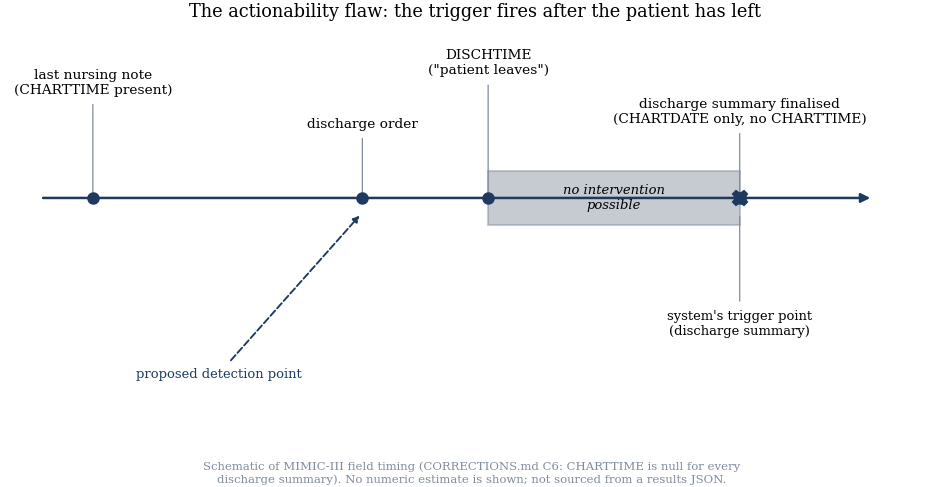

In [14]:
print("fig-disc-actionability: no result file is read by this cell.")
print("This figure is a schematic of a MIMIC-III field-availability fact (accord/CORRECTIONS.md, C6):")
print("  nursing notes carry CHARTTIME (a timestamp); discharge summaries carry only CHARTDATE (a date).")
print("No numeric estimate is plotted, so there is no CI to attach and nothing to source from a JSON file.")

fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.set_xlim(0, 10.5)
ax.set_ylim(0, 4.0)
ax.axis("off")

line_y = 2.3
events = [
    (1.0, "last nursing note\n(CHARTTIME present)", 3.35),
    (4.0, "discharge order", 3.0),
    (5.4, "DISCHTIME\n(\"patient leaves\")", 3.55),
    (8.2, "discharge summary finalised\n(CHARTDATE only, no CHARTTIME)", 3.05),
]
ax.annotate("", xy=(9.7, line_y), xytext=(0.4, line_y),
             arrowprops=dict(arrowstyle="-|>", color=DARK, lw=1.2))
for x, label, ytext in events:
    ax.plot([x], [line_y], marker="o", color=DARK, markersize=5, zorder=4)
    ax.annotate(label, (x, line_y), xytext=(x, ytext), ha="center", va="bottom", fontsize=8.0,
                 arrowprops=dict(arrowstyle="-", color=MID, lw=0.6))

ax.axvspan(5.4, 8.2, ymin=(line_y - 0.28) / 4.0, ymax=(line_y + 0.28) / 4.0, color=MID, alpha=0.45, zorder=1)
ax.text((5.4 + 8.2) / 2, line_y, "no intervention\npossible", ha="center", va="center",
         fontsize=8.0, style="italic", zorder=5)

ax.plot([8.2], [line_y], marker="X", color=DARK, markersize=7, zorder=4)
ax.annotate("system's trigger point\n(discharge summary)", xy=(8.2, line_y - 0.15),
             xytext=(8.2, 1.15), ha="center", va="top", fontsize=8.0,
             arrowprops=dict(arrowstyle="-", color=MID, lw=0.6))

ax.annotate("proposed detection point", xy=(4.0, line_y - 0.15), xytext=(2.4, 0.55),
             fontsize=8.0, ha="center", va="top", color=DARK,
             arrowprops=dict(arrowstyle="-|>", color=DARK, lw=0.9, linestyle="--"))

if SHOW_INFIGURE_TITLES: ax.set_title("The actionability flaw: the trigger fires after the patient has left", fontsize=8.5, pad=8)
fig.tight_layout(rect=[0, 0.10, 1, 1])
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
          "Schematic of MIMIC-III field timing (CORRECTIONS.md C6: CHARTTIME is null for every\n"
          "discharge summary). No numeric estimate is shown; not sourced from a results JSON.",
          ha="center", fontsize=8.0, color=MID)

save_fig(fig, "fig-disc-actionability.pdf")
plt.show()

## Figure 12: `fig-met-exchange`

**Caption.** What each summary statistic trades on this evaluation set: forgone true positives
against gained true negatives, with the four compared systems plotted in the same coordinates.

**Reads:** `results/accord/diag/step3_baselines.json` (the confusion-matrix counts for all four
systems; the indifference lines are closed-form (PABAK, balanced accuracy) or numerically
root-solved (MCC, `scipy.optimize.brentq`) from those counts, not fabricated curve shapes).

fig-met-exchange: values plotted
  reference system (ACCORD): TP=11, TN=18, FP=223, FN=1  (P=12, N=241, n=253)
  reference MCC: -0.0070
  ACCORD            : TP= 11 TN= 18 FP=223 FN=  1  delta_TP=+0  delta_TN=+0
  GPT-4o zero-shot  : TP=  6 TN=176 FP= 65 FN=  6  delta_TP=+5  delta_TN=+158
  GPT-4o few-shot   : TP=  7 TN=107 FP=134 FN=  5  delta_TP=+4  delta_TN=+89
  Llama 3 8B        : TP= 11 TN= 10 FP=231 FN=  1  delta_TP=+0  delta_TN=-8


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-met-exchange.pdf


/var/folders/l6/86mnt0714mqc2ff55k1qp1pw0000gn/T/ipykernel_32319/783406011.py:16: RuntimeWarning: invalid value encountered in sqrt
  den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))


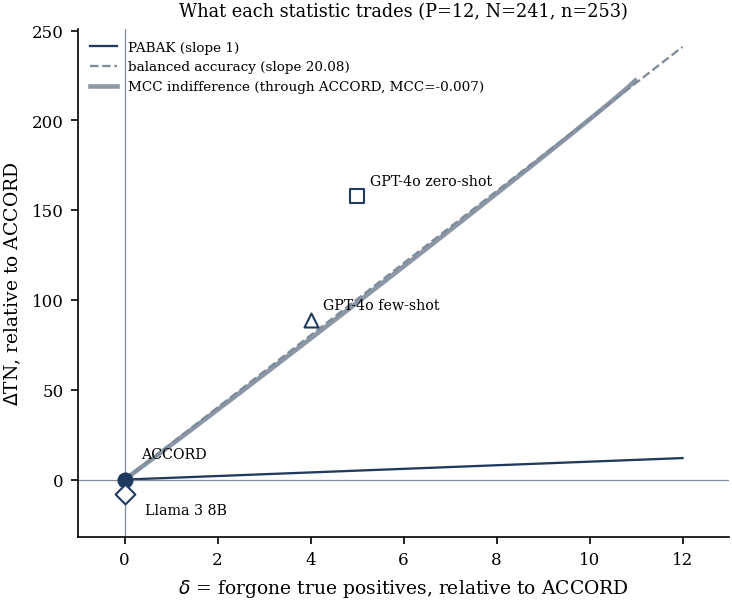

In [15]:
p_baselines = os.path.join(RESULTS_ACCORD, "diag", "step3_baselines.json")
d_baselines = json.load(open(p_baselines))
systems = {
    "ACCORD": d_baselines["accord_binary_at_0.5_253core"],
    "GPT-4o zero-shot": d_baselines["gpt4o_zeroshot"],
    "GPT-4o few-shot": d_baselines["gpt4o_fewshot"],
    "Llama 3 8B": d_baselines["llama_baseline"],
}
ref = systems["ACCORD"]
TP0, TN0, FP0, FN0 = ref["tp"], ref["tn"], ref["fp"], ref["fn"]
P = TP0 + FN0
N = TN0 + FP0

def mcc_from_counts(tp, tn, fp, fn):
    num = tp * tn - fp * fn
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return 0.0 if den == 0 else num / den

mcc0 = mcc_from_counts(TP0, TN0, FP0, FN0)

print("fig-met-exchange: values plotted")
print(f"  reference system (ACCORD): TP={TP0}, TN={TN0}, FP={FP0}, FN={FN0}  (P={P}, N={N}, n={P + N})")
print(f"  reference MCC: {mcc0:.4f}")
for name, s in systems.items():
    delta = TP0 - s["tp"]
    dtn = s["tn"] - TN0
    print(f"  {name:18s}: TP={s['tp']:3d} TN={s['tn']:3d} FP={s['fp']:3d} FN={s['fn']:3d}  delta_TP={delta:+d}  delta_TN={dtn:+d}")

fig, ax = plt.subplots(figsize=(5.6, 4.4))
d = np.linspace(0, P, 200)
ax.plot(d, d, color=DARK, linewidth=1.1, label="PABAK (slope 1)")
slope_ba = N / P
ax.plot(d, d * slope_ba, color=MID, linewidth=1.1, linestyle="--", label=f"balanced accuracy (slope {slope_ba:.2f})")

# MCC indifference curve through ACCORD's own operating point, traced numerically: for
# each delta (forgone TPs), solve for the TN that holds MCC constant at mcc0.
deltas = np.linspace(0, P, 60)
dtn_curve = []
for delta in deltas:
    tp = TP0 - delta
    fn = P - tp

    def f(tn):
        fp = N - tn
        return mcc_from_counts(tp, tn, fp, fn) - mcc0

    try:
        tn_sol = brentq(f, 0, N)
        dtn_curve.append(tn_sol - TN0)
    except ValueError:
        dtn_curve.append(np.nan)
ax.plot(deltas, dtn_curve, color=MID, linewidth=2.2, alpha=0.9, label=f"MCC indifference (through ACCORD, MCC={mcc0:.3f})")

markers = {"ACCORD": "o", "GPT-4o zero-shot": "s", "GPT-4o few-shot": "^", "Llama 3 8B": "D"}
label_offset = {"ACCORD": (8, 10), "GPT-4o zero-shot": (6, 5), "GPT-4o few-shot": (6, 5), "Llama 3 8B": (10, -10)}
for name, s in systems.items():
    delta = TP0 - s["tp"]
    dtn = s["tn"] - TN0
    ax.scatter([delta], [dtn], marker=markers[name], s=45, color=DARK,
                facecolor="white" if name != "ACCORD" else DARK, zorder=5)
    ax.annotate(name, (delta, dtn), textcoords="offset points", xytext=label_offset[name], fontsize=8.0)

ax.axhline(0, color=MID, linewidth=0.6)
ax.axvline(0, color=MID, linewidth=0.6)
ax.set_xlabel(r"$\delta$ = forgone true positives, relative to ACCORD")
ax.set_ylabel(r"$\Delta$TN, relative to ACCORD")
ax.set_xlim(-1, P + 1)
ax.set_ylim(-32, N + 10)
ax.legend(loc="upper left", fontsize=8.0, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
if SHOW_INFIGURE_TITLES: ax.set_title(f"What each statistic trades (P={P}, N={N}, n={P + N})", fontsize=8.5)

save_fig(fig, "fig-met-exchange.pdf")
plt.show()

## Figure 13: `fig-exemplar`

**Caption.** The check that was not run, drawn as a schematic. The rule fires on a conflict between
two sets of medication mentions; the exemplar shown is chosen by position instead. Slots are
abstract and no clinical text appears.

**Reads:** `results/accord/exemplar/exemplar_correctness_recomputed.json` (`rule_1_2_pooled`, the
only numeric content on this figure). Slot labels (M1..M5, CONT/CESS) are abstract action-tag codes,
not real mention text.

fig-exemplar: values plotted
  rule_1_2_pooled: n_wrong=65, n_resolved=137, defect_rate=0.4745


saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-exemplar.pdf


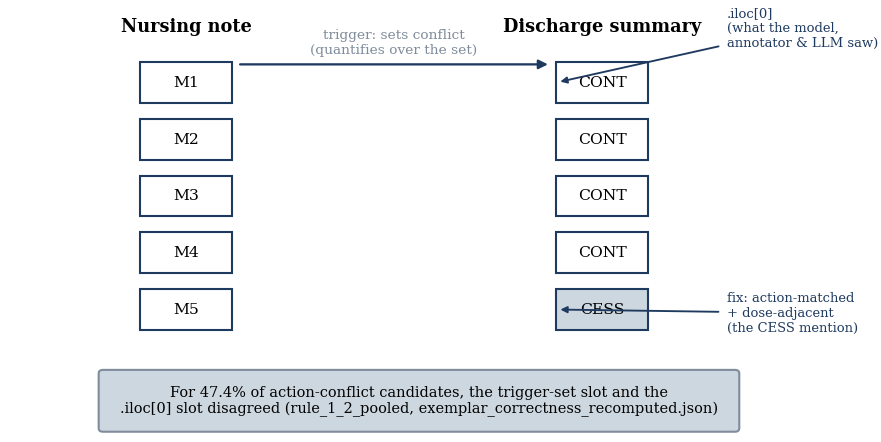

In [16]:
p_exemplar = os.path.join(RESULTS_ACCORD, "exemplar", "exemplar_correctness_recomputed.json")
d_exemplar = json.load(open(p_exemplar))
ex = d_exemplar["rule_1_2_pooled"]
defect_rate = ex["n_wrong"] / ex["n_resolved"]

print("fig-exemplar: values plotted")
print(f"  rule_1_2_pooled: n_wrong={ex['n_wrong']}, n_resolved={ex['n_resolved']}, defect_rate={defect_rate:.4f}")

fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

col_x = {"Nursing note": 2.2, "Discharge summary": 7.2}
for label, x in col_x.items():
    ax.text(x, 5.6, label, ha="center", fontsize=8.5, weight="bold")

nurse_tags = ["M1", "M2", "M3", "M4", "M5"]
disch_tags = ["CONT", "CONT", "CONT", "CONT", "CESS"]
for i in range(5):
    y = 4.9 - i * 0.78
    ax.add_patch(mpatches.Rectangle((col_x["Nursing note"] - 0.55, y - 0.28), 1.1, 0.56,
                                      facecolor="white", edgecolor=DARK))
    ax.text(col_x["Nursing note"], y, nurse_tags[i], ha="center", va="center", fontsize=8.0)
    fc = FILL if i == 4 else "white"
    ax.add_patch(mpatches.Rectangle((col_x["Discharge summary"] - 0.55, y - 0.28), 1.1, 0.56,
                                      facecolor=fc, edgecolor=DARK))
    ax.text(col_x["Discharge summary"], y, disch_tags[i], ha="center", va="center", fontsize=8.0)

ax.annotate("", xy=(col_x["Discharge summary"] - 0.6, 5.15), xytext=(col_x["Nursing note"] + 0.6, 5.15),
             arrowprops=dict(arrowstyle="-|>", color=DARK, lw=1.1))
ax.text((col_x["Nursing note"] + col_x["Discharge summary"]) / 2, 5.3,
         "trigger: sets conflict\n(quantifies over the set)", ha="center", fontsize=8.0, color=MID)

y0 = 4.9
y4 = 4.9 - 4 * 0.78
ax.annotate(".iloc[0]\n(what the model,\nannotator & LLM saw)",
             xy=(col_x["Discharge summary"] - 0.55, y0), xytext=(col_x["Discharge summary"] + 1.5, y0 + 0.5),
             fontsize=8.0, color=DARK, arrowprops=dict(arrowstyle="-|>", color=DARK, lw=0.9))
ax.annotate("fix: action-matched\n+ dose-adjacent\n(the CESS mention)",
             xy=(col_x["Discharge summary"] - 0.55, y4), xytext=(col_x["Discharge summary"] + 1.5, y4 - 0.3),
             fontsize=8.0, color=DARK, arrowprops=dict(arrowstyle="-|>", color=DARK, lw=0.9))

ax.add_patch(mpatches.FancyBboxPatch((1.2, 0.15), 7.6, 0.75,
             boxstyle="round,pad=0.05", facecolor=FILL, edgecolor=MID))
ax.text(5.0, 0.52,
         f"For {defect_rate * 100:.1f}% of action-conflict candidates, the trigger-set slot and the\n"
         ".iloc[0] slot disagreed (rule_1_2_pooled, exemplar_correctness_recomputed.json)",
         ha="center", va="center", fontsize=8.0)

fig.tight_layout()

save_fig(fig, "fig-exemplar.pdf")
plt.show()

## Final: verify all thirteen exist, then copy to Drive

Checks that every figure this notebook is supposed to produce is actually on disk (run any missing
figure cells above first), then, if running in Colab, copies the thirteen PDFs back to Drive.

In [17]:
EXPECTED = [
    "fig-pipeline-status.pdf",
    "fig-intro-headline.pdf",
    "fig-rule-precision.pdf",
    "fig-prevalence-response.pdf",
    "fig-falsification.pdf",
    "fig-power.pdf",
    "fig-forest.pdf",
    "fig-disc-strata.pdf",
    "fig-scaling.pdf",
    "fig-threshold-surface.pdf",
    "fig-disc-actionability.pdf",
    "fig-met-exchange.pdf",
    "fig-exemplar.pdf",
]

print(f"checking that all {len(EXPECTED)} thesis figures are present in {FIGDIR}")
missing = []
for name in EXPECTED:
    path = os.path.join(FIGDIR, name)
    ok = os.path.exists(path)
    print(f"  {'ok     ' if ok else 'MISSING'}  {name}")
    if not ok:
        missing.append(name)

if missing:
    print(f"\n{len(missing)} of {len(EXPECTED)} missing. Run the missing figure cells above, then re-run this cell.")
else:
    print(f"\nall {len(EXPECTED)} figures present.")

if not missing and IN_COLAB:
    OUT_DRIVE = "/content/drive/MyDrive/This is paper/02_figures"
    n = 0
    for name in EXPECTED:
        shutil.copy(os.path.join(FIGDIR, name), os.path.join(OUT_DRIVE, name))
        n += 1
    print(f"copied {n} figures to {OUT_DRIVE}")
elif not IN_COLAB:
    print("not running in Colab; skipping the copy-to-Drive step (figures are already in the local repository checkout).")

checking that all 13 thesis figures are present in /Users/rickygole/provenance-encoder/accord/thesis/figures
  ok       fig-pipeline-status.pdf
  ok       fig-intro-headline.pdf
  ok       fig-rule-precision.pdf
  ok       fig-prevalence-response.pdf
  ok       fig-falsification.pdf
  ok       fig-power.pdf
  ok       fig-forest.pdf
  ok       fig-disc-strata.pdf
  ok       fig-scaling.pdf
  ok       fig-threshold-surface.pdf
  ok       fig-disc-actionability.pdf
  ok       fig-met-exchange.pdf
  ok       fig-exemplar.pdf

all 13 figures present.
not running in Colab; skipping the copy-to-Drive step (figures are already in the local repository checkout).
